# E-commerce Purchase Intent & Expected Value / Ý định mua và giá trị kỳ vọng

Tôi kết hợp phân loại phiên mua hàng với một bài mô phỏng chọn hành động theo EV.
**Input:** 12.330 phiên trong bộ Online Shoppers của UCI. **Output:** xác suất mua
lịch sử, metric test, biểu đồ calibration và EV theo các giả định tùy chỉnh.

I compare purchase-probability models and explore an illustrative decision rule.
Run all cells with the [pinned environment](../README.md). Data download is cached locally;
an existing official CSV can be supplied with `SHOPPERS_CSV`.

## Phạm vi / Scope

Đây là bài phân tích offline trên đặc trưng tổng hợp của phiên. Dữ liệu không có
snapshot tại thời điểm can thiệp hoặc nhật ký ngẫu nhiên hóa khuyến mãi. Vì vậy,
xác suất dự đoán mô tả dữ liệu lịch sử, chưa phải xác suất phản thực khi không khuyến mãi.
Tôi bỏ `PageValues` khỏi mô hình chính vì metadata mô tả đặc trưng gắn với giá trị giao dịch;
chưa xác định được chính xác thời điểm tính. Các đặc trưng còn lại cũng cần được kiểm tra
tính khả dụng theo thời điểm trước khi dùng cho một hành động trong phiên.

These are offline session features. Their intervention-time availability and treatment
history are unknown. Dropping PageValues is a conservative feature choice, not proof
that all remaining inputs are available for real-time decisions.

In [1]:
import hashlib
import io
import os
from pathlib import Path
import urllib.request
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import (
    roc_auc_score, average_precision_score, log_loss, brier_score_loss,
    classification_report, confusion_matrix,
)
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

SEED = 42

## 1. Tải và kiểm tra nguồn / Load verified data

Nguồn: Sakar & Kastro (2018), [UCI dataset 468](https://doi.org/10.24432/C5F88Q),
giấy phép [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/).
Tôi dùng CSV gốc, không thay dữ liệu tổng hợp khi tải lỗi. Checksum giúp phát hiện
bản dữ liệu thay đổi. / Use the original CSV with a checksum and local cache;
network errors remain visible.

In [2]:
DATA_URL = 'https://archive.ics.uci.edu/static/public/468/online+shoppers+purchasing+intention+dataset.zip'
DATA_SHA256 = 'b3055ee355f59134d851d32641183cb4a8b45def7124d2f50442a042f358e0d9'
cwd = Path.cwd()
labs_dir = cwd.parent if cwd.name == 'notebooks' else (cwd if cwd.name == 'labs' else cwd / 'labs')
override = os.environ.get('SHOPPERS_CSV')
csv_path = Path(override).expanduser() if override else labs_dir / 'data/online_shoppers_intention.csv'
if csv_path.exists():
    csv_bytes = csv_path.read_bytes()
elif override:
    raise FileNotFoundError(f'SHOPPERS_CSV does not exist: {csv_path}')
else:
    with urllib.request.urlopen(DATA_URL, timeout=60) as response:
        archive_bytes = response.read()
    with zipfile.ZipFile(io.BytesIO(archive_bytes)) as archive:
        csv_bytes = archive.read('online_shoppers_intention.csv')
actual_sha256 = hashlib.sha256(csv_bytes).hexdigest()
if actual_sha256 != DATA_SHA256:
    raise ValueError(f'Unexpected official CSV checksum: {actual_sha256}')
if not csv_path.exists():
    csv_path.parent.mkdir(parents=True, exist_ok=True)
    csv_path.write_bytes(csv_bytes)
df = pd.read_csv(io.BytesIO(csv_bytes))
assert df.shape == (12330, 18) and not df.columns.duplicated().any()
assert not df.isna().any().any()
print('Dataset:', df.shape, '| SHA-256:', actual_sha256)
display(df.head())

Dataset: (12330, 18) | SHA-256: b3055ee355f59134d851d32641183cb4a8b45def7124d2f50442a042f358e0d9


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


## 2. Kiểu dữ liệu và chia tập / Types and splits

Các mã OS, browser, region, traffic type là danh mục, không phải đại lượng có thứ tự.
Tôi chia phân tầng **60% train / 20% validation / 20% test**, seed 42.
Random split đo khả năng khái quát trong cùng bộ dữ liệu; chưa đo chuyển dịch theo thời gian.

ID-coded categories are one-hot encoded. There are no complete timestamps for a reliable
chronological holdout; this stratified random split is an offline benchmark.

In [3]:
required = {
    'Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration',
    'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues',
    'SpecialDay', 'Month', 'OperatingSystems', 'Browser', 'Region', 'TrafficType',
    'VisitorType', 'Weekend', 'Revenue',
}
assert set(df.columns) == required
target = df['Revenue'].astype(str).str.strip().str.lower().map({'true': 1, 'false': 0, '1': 1, '0': 0})
if target.isna().any():
    raise ValueError('Unrecognized Revenue value')
y = target.astype('int64')
assert y.value_counts().to_dict() == {0: 10422, 1: 1908}
X = df.drop(columns=['Revenue', 'PageValues']).copy()
categorical_cols = ['Month', 'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'VisitorType', 'Weekend']
for column in categorical_cols:
    X[column] = X[column].astype(str)
numeric_cols = [column for column in X.columns if column not in categorical_cols]
assert np.isfinite(X[numeric_cols].to_numpy(dtype=float)).all()
X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
X_train, X_valid, y_train, y_valid = train_test_split(
    X_temp, y_temp, test_size=0.25, stratify=y_temp, random_state=SEED
)
assert not set(X_train.index) & set(X_valid.index)
assert not set(X_train.index) & set(X_test.index)
assert not set(X_valid.index) & set(X_test.index)
assert len(X_train) + len(X_valid) + len(X_test) == len(df)
print('Train/validation/test:', len(y_train), len(y_valid), len(y_test))
print('Positive rate:', float(y.mean()))

Train/validation/test: 7398 2466 2466
Positive rate: 0.15474452554744525


## 3. Tiền xử lý và đối chứng / Preprocessing and baselines

Mỗi pipeline có bộ tiền xử lý riêng, chỉ fit trên train. Tôi dùng Dummy (tỷ lệ mua
trong train), Logistic Regression và Random Forest. Tôi bỏ class weighting vì
bài EV cần xác suất phản ánh tỷ lệ lớp quan sát; class weights sẽ đổi mục tiêu fit.

Pipelines independently fit train-only preprocessing. Unweighted models are compared
with a constant-prior baseline; calibration still needs to be checked empirically.

In [4]:
preprocessor = ColumnTransformer([
    ('num', Pipeline([('imputer', SimpleImputer(strategy='median')), ('scale', StandardScaler())]), numeric_cols),
    ('cat', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')),
                      ('onehot', OneHotEncoder(handle_unknown='ignore'))]), categorical_cols),
])
candidate_models = {
    'DummyPrior': DummyClassifier(strategy='prior'),
    'LogisticRegression': LogisticRegression(max_iter=2000, random_state=SEED),
    'RandomForest': RandomForestClassifier(
        n_estimators=200, max_depth=10, min_samples_leaf=5, random_state=SEED, n_jobs=2
    ),
}
fitted_models = {}
validation_rows = []

def probability_metrics(actual, probabilities):
    probabilities = np.asarray(probabilities, dtype=float)
    assert probabilities.shape == (len(actual),)
    assert np.isfinite(probabilities).all() and ((0 <= probabilities) & (probabilities <= 1)).all()
    return {
        'roc_auc': float(roc_auc_score(actual, probabilities)),
        'average_precision': float(average_precision_score(actual, probabilities)),
        'log_loss': float(log_loss(actual, probabilities, labels=[0, 1])),
        'brier': float(brier_score_loss(actual, probabilities)),
    }

for name, estimator in candidate_models.items():
    pipeline = Pipeline([('preprocess', clone(preprocessor)), ('model', estimator)])
    pipeline.fit(X_train, y_train)
    fitted_models[name] = pipeline
    validation_rows.append({'model': name, **probability_metrics(y_valid, pipeline.predict_proba(X_valid)[:, 1])})
validation_table = pd.DataFrame(validation_rows).set_index('model')
display(validation_table.sort_values('log_loss'))

,roc_auc,average_precision,log_loss,brier
model,,,,
RandomForest,0.767614,0.359418,0.368343,0.114889
LogisticRegression,0.740991,0.320060,0.379165,0.118370
DummyPrior,0.500000,0.154501,0.430438,0.130631


## 4. Chọn mô hình và đánh giá test / Select, then test

Tôi chọn **validation log loss thấp nhất**, dùng Brier để phá hòa, vì EV dùng trực tiếp
xác suất. AUC đo xếp hạng nên được ghi thêm. Test được xem sau khi chốt mô hình;
dữ liệu test không tham gia fit hoặc chọn mô hình.

Lowest validation log loss selects the probability model. Held-out test metrics are
reported after selection, including the fixed prior baseline for context.

In [5]:
best_name = validation_table.sort_values(['log_loss', 'brier']).index[0]
best_model = fitted_models[best_name]
test_scores = best_model.predict_proba(X_test)[:, 1]
selected_test_metrics = probability_metrics(y_test, test_scores)
dummy_test_metrics = probability_metrics(y_test, fitted_models['DummyPrior'].predict_proba(X_test)[:, 1])
print('Selected using validation only:', best_name)
test_table = pd.DataFrame([selected_test_metrics, dummy_test_metrics], index=['selected', 'prior_baseline'])
display(test_table)
threshold_predictions = (test_scores >= 0.5).astype(int)
print('Classification at a fixed threshold of 0.5:')
print(classification_report(y_test, threshold_predictions, digits=4, zero_division=0))
print(confusion_matrix(y_test, threshold_predictions))

Selected using validation only: RandomForest


,roc_auc,average_precision,log_loss,brier
selected,0.757777,0.355999,0.371005,0.115860
prior_baseline,0.500000,0.154907,0.431127,0.130911


Classification at a fixed threshold of 0.5:
              precision    recall  f1-score   support

           0     0.8453    0.9990    0.9158      2084
           1     0.3333    0.0026    0.0052       382

    accuracy                         0.8447      2466
   macro avg     0.5893    0.5008    0.4605      2466
weighted avg     0.7660    0.8447    0.7747      2466

[[2082    2]
 [ 381    1]]


,bucket,avg_pred,actual_rate,n
0,"(0.0009599999999999999, 0.0175]",0.009001,0.008065,248
1,"(0.0175, 0.0461]",0.030168,0.020325,246
2,"(0.0461, 0.0826]",0.064755,0.040650,246
3,"(0.0826, 0.114]",0.098610,0.105263,247
4,"(0.114, 0.149]",0.131951,0.121951,246
5,"(0.149, 0.182]",0.165369,0.149798,247
6,"(0.182, 0.216]",0.198858,0.195122,246
7,"(0.216, 0.248]",0.231987,0.214575,247
8,"(0.248, 0.312]",0.274232,0.276423,246
9,"(0.312, 0.537]",0.379875,0.417004,247


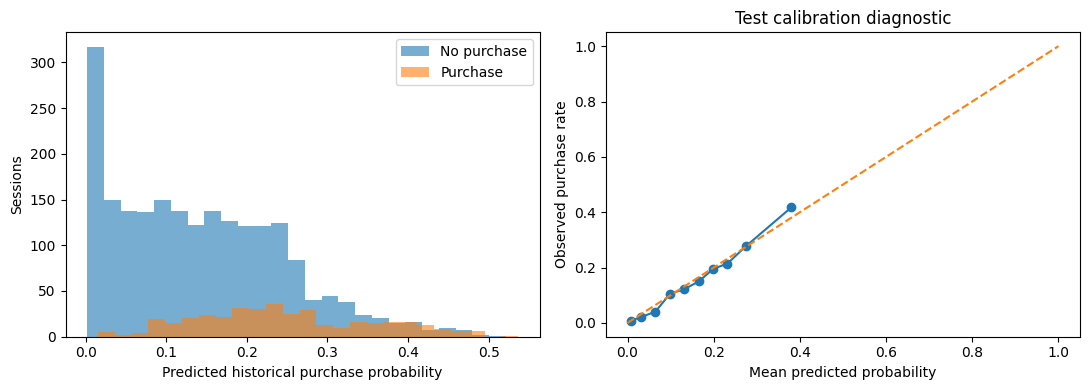

In [6]:
calib_df = pd.DataFrame({'p_buy': test_scores, 'actual': y_test.to_numpy()})
calib_df['bucket'] = pd.qcut(calib_df['p_buy'], q=10, duplicates='drop')
bucket_summary = calib_df.groupby('bucket', observed=True).agg(
    avg_pred=('p_buy', 'mean'), actual_rate=('actual', 'mean'), n=('actual', 'size')
).reset_index()
assert int(bucket_summary['n'].sum()) == len(y_test)
display(bucket_summary)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for label, title in [(0, 'No purchase'), (1, 'Purchase')]:
    axes[0].hist(test_scores[y_test.to_numpy() == label], bins=25, alpha=0.6, label=title)
axes[0].set_xlabel('Predicted historical purchase probability')
axes[0].set_ylabel('Sessions')
axes[0].legend()
axes[1].plot(bucket_summary['avg_pred'], bucket_summary['actual_rate'], marker='o')
axes[1].plot([0, 1], [0, 1], linestyle='--')
axes[1].set_xlabel('Mean predicted probability')
axes[1].set_ylabel('Observed purchase rate')
axes[1].set_title('Test calibration diagnostic')
plt.tight_layout()
plt.show()

## 5. Mô phỏng expected value / Expected-value scenario

Tôi **giả định** xác suất lịch sử là xác suất gốc, margin = 50, chi phí giảm giá = 10
trên đơn mua, retargeting = 2 trên mỗi phiên được tác động. Đây là đơn vị tiền tùy chọn.
Uplift trong hai hàm dưới là giả định, không được học từ dữ liệu này.

- `EV_no_action = p × margin`
- `EV_discount = clip(p + assumed_uplift, 0, 1) × (margin − discount_cost)`
- `EV_retarget = clip(p + assumed_uplift, 0, 1) × margin − retarget_cost`

Treating historical probability as an untreated baseline is an **unverified scenario assumption**.
An EV-maximizing rule must score at least as high under the same formulas by construction;
that difference is not evidence of causal or realized profit improvement.

In [7]:
BASE_MARGIN, DISCOUNT_COST, RETARGET_COST = 50.0, 10.0, 2.0
ACTION_COLS = ['EV_no_action', 'EV_discount', 'EV_retarget']

def uplift_discount(p):
    return np.clip(0.12 * (1 - np.abs(p - 0.5) * 2), 0.02, 0.12)

def uplift_retarget(p):
    return np.clip(0.05 * (1 - np.abs(p - 0.45) * 1.6), 0.01, 0.05)

def compute_expected_values(p, uplift_scale=1.0):
    p = np.asarray(p, dtype=float)
    if p.ndim != 1 or not np.isfinite(p).all() or ((p < 0) | (p > 1)).any():
        raise ValueError('Probabilities must be a finite 1-D array in [0, 1]')
    if not np.isfinite(uplift_scale) or uplift_scale < 0:
        raise ValueError('uplift_scale must be finite and non-negative')
    if not (0 <= DISCOUNT_COST <= BASE_MARGIN and RETARGET_COST >= 0):
        raise ValueError('Invalid cost assumptions')
    return pd.DataFrame({
        'p_buy': p,
        'EV_no_action': p * BASE_MARGIN,
        'EV_discount': np.clip(p + uplift_scale * uplift_discount(p), 0, 1) * (BASE_MARGIN - DISCOUNT_COST),
        'EV_retarget': np.clip(p + uplift_scale * uplift_retarget(p), 0, 1) * BASE_MARGIN - RETARGET_COST,
    })

ev_df = compute_expected_values(test_scores)
ev_df['best_action'] = ev_df[ACTION_COLS].idxmax(axis=1)
print('Actions under the assumed scenario:')
print(ev_df['best_action'].value_counts())
display(ev_df.head())

Actions under the assumed scenario:
best_action
EV_no_action    1540
EV_discount      718
EV_retarget      208
Name: count, dtype: int64


,p_buy,EV_no_action,EV_discount,EV_retarget,best_action
0,0.053498,2.674896,2.939917,1.588888,EV_discount
1,0.151984,7.599180,7.538387,6.907115,EV_no_action
2,0.136576,6.828824,6.774193,6.075129,EV_no_action
3,0.014715,0.735735,1.388588,-0.505406,EV_discount
4,0.071443,3.572135,3.657708,2.557906,EV_discount


## 6. Đối chiếu rule và độ nhạy / Rule comparison and sensitivity

Rule minh họa: p > 0,7 → không ưu đãi; 0,4 < p ≤ 0,7 → giảm giá; còn lại → retarget.
Tôi giữ rule và EV đã chọn trong kịch bản gốc, rồi giảm uplift về 50% và 0%.
Giữ action cố định giúp thấy rủi ro khi giả định sai; tối ưu lại action ở mỗi dòng
chỉ cho một mức tham chiếu biết trước kịch bản.

Freeze the original choices while varying assumed uplift. The per-scenario oracle
is a mathematical upper reference, not a deployable estimate of business gain.

In [8]:
rule_actions = np.where(test_scores > 0.7, 'EV_no_action',
                        np.where(test_scores > 0.4, 'EV_discount', 'EV_retarget'))
frozen_ev_actions = ev_df['best_action'].to_numpy()

def action_values(table, actions):
    indexes = pd.Index(ACTION_COLS).get_indexer(actions)
    if (indexes < 0).any():
        raise ValueError('Unknown action')
    return table[ACTION_COLS].to_numpy()[np.arange(len(table)), indexes]

sensitivity_rows = []
for scale in [1.0, 0.5, 0.0]:
    scenario = compute_expected_values(test_scores, uplift_scale=scale)
    sensitivity_rows.append({
        'assumed_uplift_scale': scale,
        'no_action_ev': float(scenario['EV_no_action'].mean()),
        'frozen_rule_ev': float(action_values(scenario, rule_actions).mean()),
        'frozen_ev_policy': float(action_values(scenario, frozen_ev_actions).mean()),
        'scenario_oracle_ev': float(scenario[ACTION_COLS].max(axis=1).mean()),
    })
sensitivity_table = pd.DataFrame(sensitivity_rows)
display(sensitivity_table)
scenario_gain = float(sensitivity_table.iloc[0]['frozen_ev_policy'] - sensitivity_table.iloc[0]['frozen_rule_ev'])
assert scenario_gain >= -1e-12
no_uplift = compute_expected_values(np.array([0.0, 0.5, 1.0]), uplift_scale=0)
assert (no_uplift[ACTION_COLS].idxmax(axis=1) == 'EV_no_action').all()
boundary = compute_expected_values(np.array([0.0, 1.0]))
assert np.isfinite(boundary[ACTION_COLS].to_numpy()).all()
try:
    compute_expected_values(np.array([np.nan]))
except ValueError:
    pass
else:
    raise AssertionError('Invalid probability accepted')
LAB_RESULT = {
    'data_rows': len(df), 'data_sha256': actual_sha256, 'features': X.shape[1],
    'train_rows': len(y_train), 'validation_rows': len(y_valid), 'test_rows': len(y_test),
    'selection_metric': 'validation_log_loss', 'selected_model': best_name,
    'validation_metrics': validation_table.to_dict(orient='index'),
    'test_metrics': selected_test_metrics, 'prior_test_metrics': dummy_test_metrics,
    'assumed_ev_difference_per_session': scenario_gain,
    'sensitivity': sensitivity_rows,
}
print(LAB_RESULT)

,assumed_uplift_scale,no_action_ev,frozen_rule_ev,frozen_ev_policy,scenario_oracle_ev
0,1.0,7.92287,7.234902,8.079576,8.079576
1,0.5,7.92287,6.538374,7.868635,7.964481
2,0.0,7.92287,5.841846,7.657694,7.922870


{'data_rows': 12330, 'data_sha256': 'b3055ee355f59134d851d32641183cb4a8b45def7124d2f50442a042f358e0d9', 'features': 16, 'train_rows': 7398, 'validation_rows': 2466, 'test_rows': 2466, 'selection_metric': 'validation_log_loss', 'selected_model': 'RandomForest', 'validation_metrics': {'DummyPrior': {'roc_auc': 0.5, 'average_precision': 0.15450121654501217, 'log_loss': 0.4304383720398553, 'brier': 0.13063066371664278}, 'LogisticRegression': {'roc_auc': 0.7409908293837372, 'average_precision': 0.3200599223815597, 'log_loss': 0.379165166887236, 'brier': 0.11836995338739317}, 'RandomForest': {'roc_auc': 0.767613940343788, 'average_precision': 0.35941830792543183, 'log_loss': 0.3683431686871613, 'brier': 0.11488920586306747}}, 'test_metrics': {'roc_auc': 0.7577767784466038, 'average_precision': 0.35599906133173453, 'log_loss': 0.3710052604727534, 'brier': 0.11586019996399849}, 'prior_test_metrics': {'roc_auc': 0.5, 'average_precision': 0.1549067315490673, 'log_loss': 0.43112679730813547, 'bri

## Điều tôi rút ra và bước tiếp theo / Lessons and next work

Tôi đã nối được dữ liệu → tiền xử lý → đối chứng → chọn mô hình → đánh giá xác suất →
mô phỏng quyết định. Bước tiếp theo là có snapshot theo thời điểm, xác nhận đặc trưng
trước can thiệp, kiểm tra calibration ngoài mẫu và đo treatment bằng thử nghiệm phù hợp.
Margin theo SKU, ngân sách và giới hạn ưu đãi cần dữ liệu riêng.

This exercise links modeling to a decision calculation and exposes the assumptions
between them. A real promotion policy would require treatment data, timing checks,
calibrated probabilities and an independent outcome evaluation.